In [1]:
import pandas as pd
import numpy as np
import mplfinance as mpf
from datetime import datetime, timedelta
import pandas_ta as ta
import os

# Import tdata package functionality
from packages.tdata.ingestion import get_rts_data, extract_tickers, get_figis, fetch_ohlcv_data
from packages.tdata.processing import calculate_indicators, process_file_with_indicators

# OHLCV Data Visualization Demo

This notebook demonstrates how to visualize OHLCV (Open, High, Low, Close, Volume) data and technical indicators using the tdata package. We'll cover:
1. Fetching market data
2. Calculating technical indicators
3. Visualizing various charts including:
   - Candlestick patterns with volume
   - Moving Averages (SMA)
   - Relative Strength Index (RSI)
   - MACD (Moving Average Convergence Divergence)
   - Bollinger Bands
   - ADX (Average Directional Index)
   - Stochastic Oscillator
   - On-Balance Volume (OBV)

# Loading Market Data

In this notebook, we'll demonstrate loading market data using the updated tdata package. The package now automatically handles:
1. Date conversion to pandas datetime format
2. Setting the original 'date' column as the index
3. Preserving datetime information in 'date_time' column for calculations
4. Basic data preprocessing and validation

The data will be structured with:
- DateTime index (from 'date' column) for time series operations
- `date_time` column preserved for calculations and indicators
- All standard OHLCV columns

This means you no longer need to manually convert dates or set index - these operations are handled internally by the `fetch_ohlcv_data` function.

In [2]:
# Load environment variables from .env file
TOKEN = os.getenv("TINKOFF_TOKEN")

# Set the date range for data retrieval
end_date = pd.Timestamp("2024-12-31T12:00:00Z")
start_date = end_date - timedelta(days=30)

# Define the candle interval
interval = "1hour"  # Options: 1min, 5min, 15min, 1hour, 1day, etc.

# Get tickers and their FIGIs
tickers = extract_tickers()
ticker_figis = get_figis(tickers, TOKEN)

# Fetch OHLCV data and calculate indicators
df = fetch_ohlcv_data(ticker_figis, start_date, end_date, interval, TOKEN)
# Save df as test CSV file
df.to_csv("./data/data/test_ohlcv_data.csv")

In [4]:
# Read df with index and process it with indicators
df = pd.read_csv("./data/data/test_ohlcv_data.csv", index_col='date')

# Calculate indicators and remove rows with NaN values
df = calculate_indicators(df, drop_na_rows=True)

# Print data info to verify
print("Dataset info after cleaning:")
print(f"Total rows: {len(df)}")
print("\nSample of first few rows to verify indicators:")
print(df[['close', 'rsi', 'macd_line', 'bb_middle']].head())

Dataset info after cleaning:
Total rows: 18344

Sample of first few rows to verify indicators:
                            close        rsi  macd_line  bb_middle
date                                                              
2024-12-07 09:00:00+00:00  12.311  59.400366   0.059673   12.27525
2024-12-07 10:00:00+00:00  12.303  58.219344   0.055465   12.27645
2024-12-07 11:00:00+00:00  12.314  59.414240   0.052413   12.28265
2024-12-07 12:00:00+00:00  12.330  61.154474   0.050701   12.29115
2024-12-07 13:00:00+00:00  12.331  61.266261   0.048862   12.29665


In [5]:
df.to_csv("./data/data/test_ohlcv_data_indicators.csv")
df

,figi,open,high,low,close,volume,tic,day,rsi,macd_line,...,bb_lower,bb_middle,bb_upper,vwap,adx,adx_positive,adx_negative,stoch_k,stoch_d,obv
date,,,,,,,,,,,,,,,,,,,,,
2024-12-07 09:00:00+00:00,BBG004S68614,12.330,12.330,12.307,12.311,154,AFKS,5,59.400366,0.059673,...,12.179069,12.27525,12.371431,12.087117,27.772775,20.135540,13.873865,74.820700,78.218655,-317079.0
2024-12-07 10:00:00+00:00,BBG004S68614,12.312,12.329,12.303,12.303,119,AFKS,5,58.219344,0.055465,...,12.179516,12.27645,12.373384,12.087119,27.011515,19.660747,13.909488,66.425519,73.434513,-317198.0
2024-12-07 11:00:00+00:00,BBG004S68614,12.327,12.328,12.305,12.314,79,AFKS,5,59.414240,0.052413,...,12.193041,12.28265,12.372259,12.087121,26.304796,19.192133,13.577955,60.621235,67.289152,-317119.0
2024-12-07 12:00:00+00:00,BBG004S68614,12.315,12.330,12.314,12.330,294,AFKS,5,61.154474,0.050701,...,12.219174,12.29115,12.363126,12.087128,25.685612,19.083973,13.358504,60.960917,62.669224,-316825.0
2024-12-07 13:00:00+00:00,BBG004S68614,12.328,12.331,12.316,12.331,2564,AFKS,5,61.266261,0.048862,...,12.230371,12.29665,12.362929,12.087189,25.130456,18.884604,13.144024,66.463415,62.681856,-314261.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-31 07:00:00+00:00,TCS00A107T19,4007.000,4008.000,4003.000,4005.000,1805,YDEX,1,62.897501,14.670889,...,3957.134755,3988.52500,4019.915245,3532.285399,30.889712,21.089308,11.174254,81.874434,80.708522,2603866.0
2024-12-31 08:00:00+00:00,TCS00A107T19,4005.000,4010.000,4003.500,4010.000,2128,YDEX,1,64.897684,14.534600,...,3960.817128,3990.95000,4021.082872,3532.323509,31.021947,21.383358,10.834810,82.200647,82.153182,2605994.0
2024-12-31 09:00:00+00:00,TCS00A107T19,4006.500,4010.000,4000.500,4008.000,4836,YDEX,1,63.424794,14.102641,...,3961.169863,3992.07500,4022.980137,3532.409789,30.720284,20.407612,11.781388,82.847896,82.307659,2601158.0


## Visualizing Technical Indicators

Let's create various plots to analyze the price action and technical indicators:

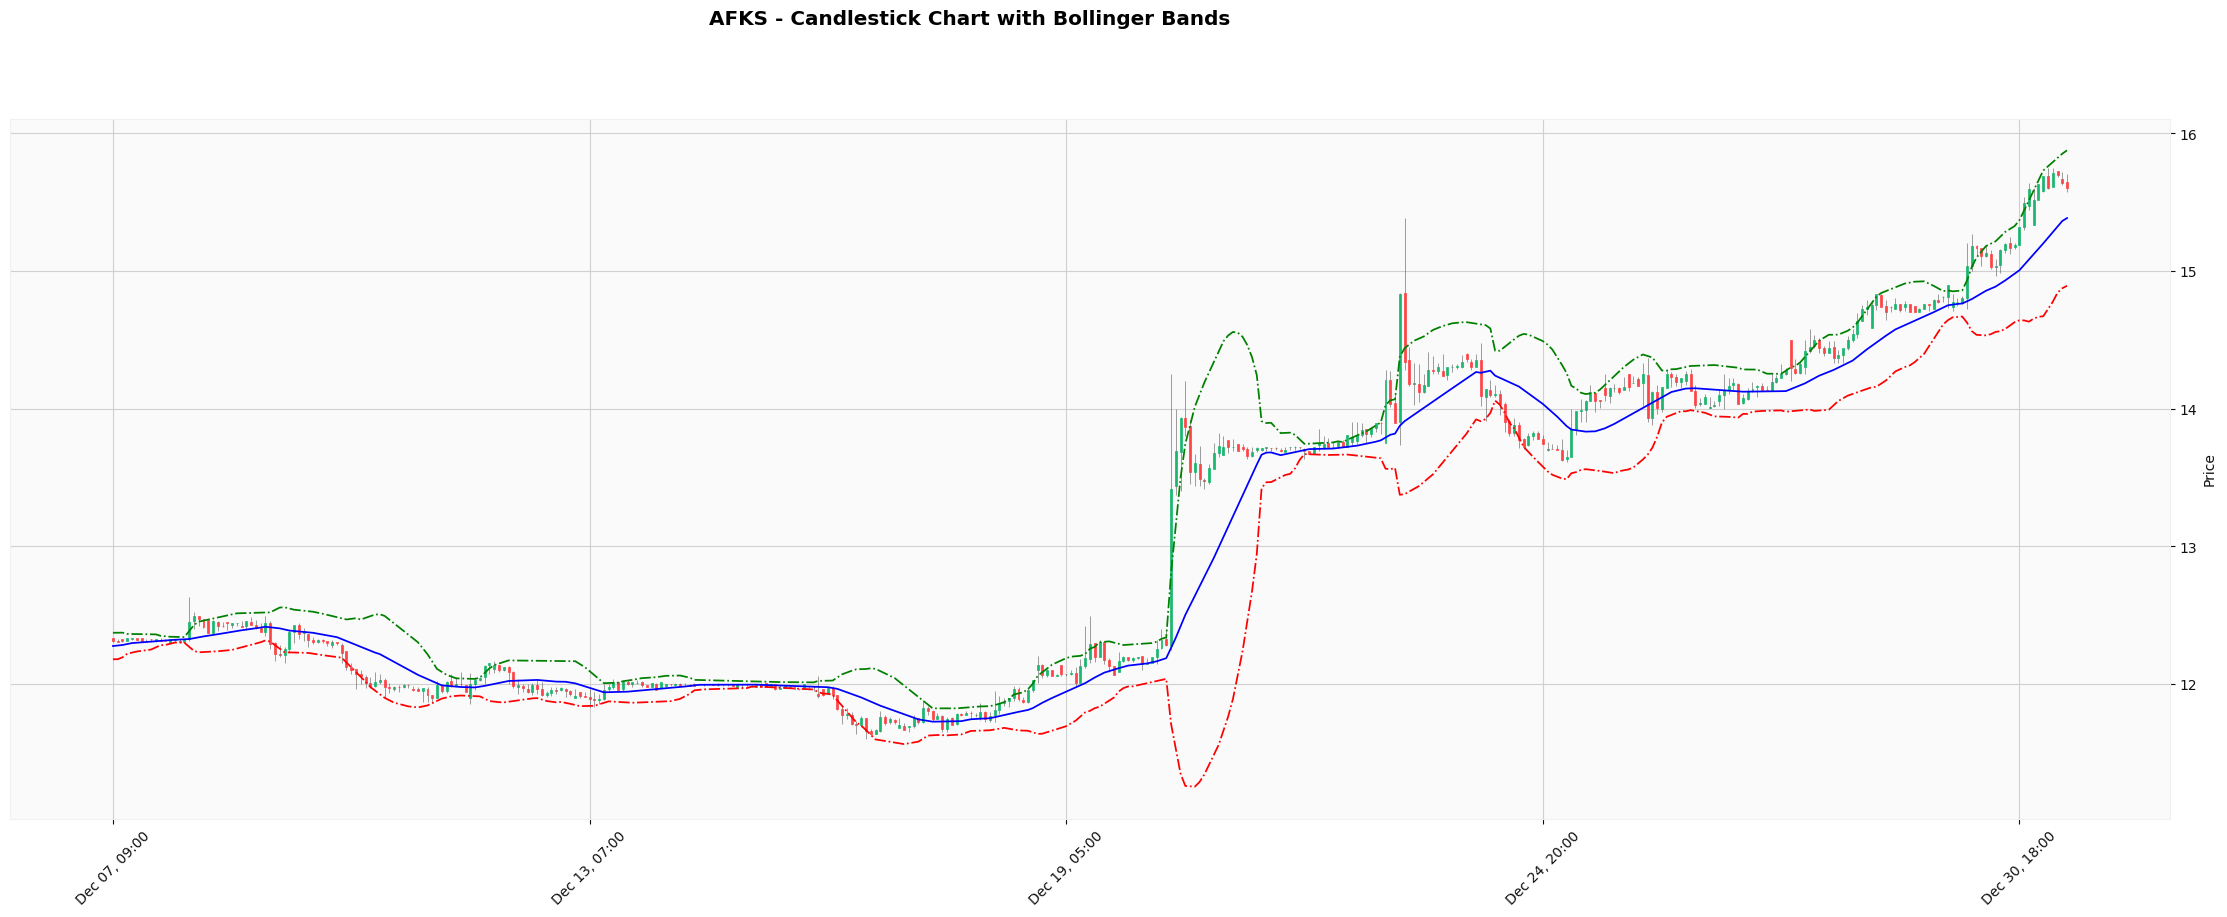

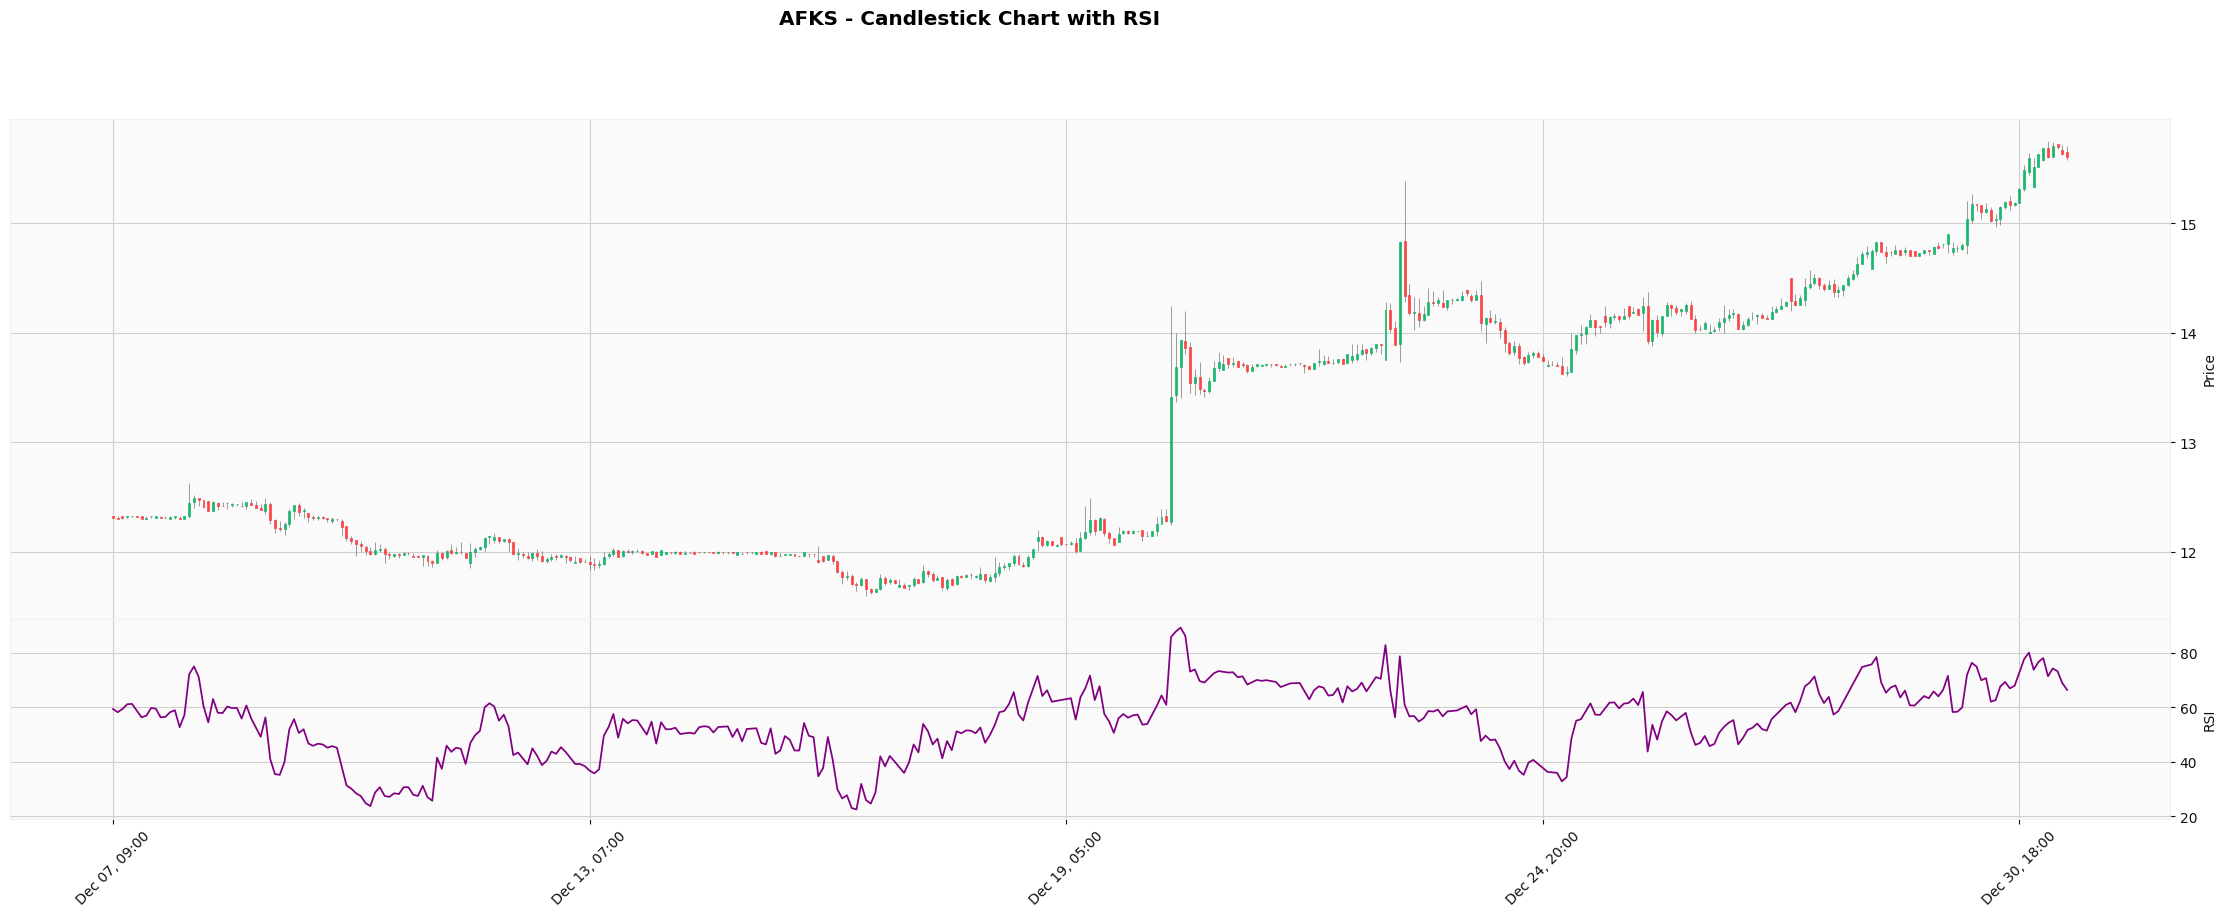

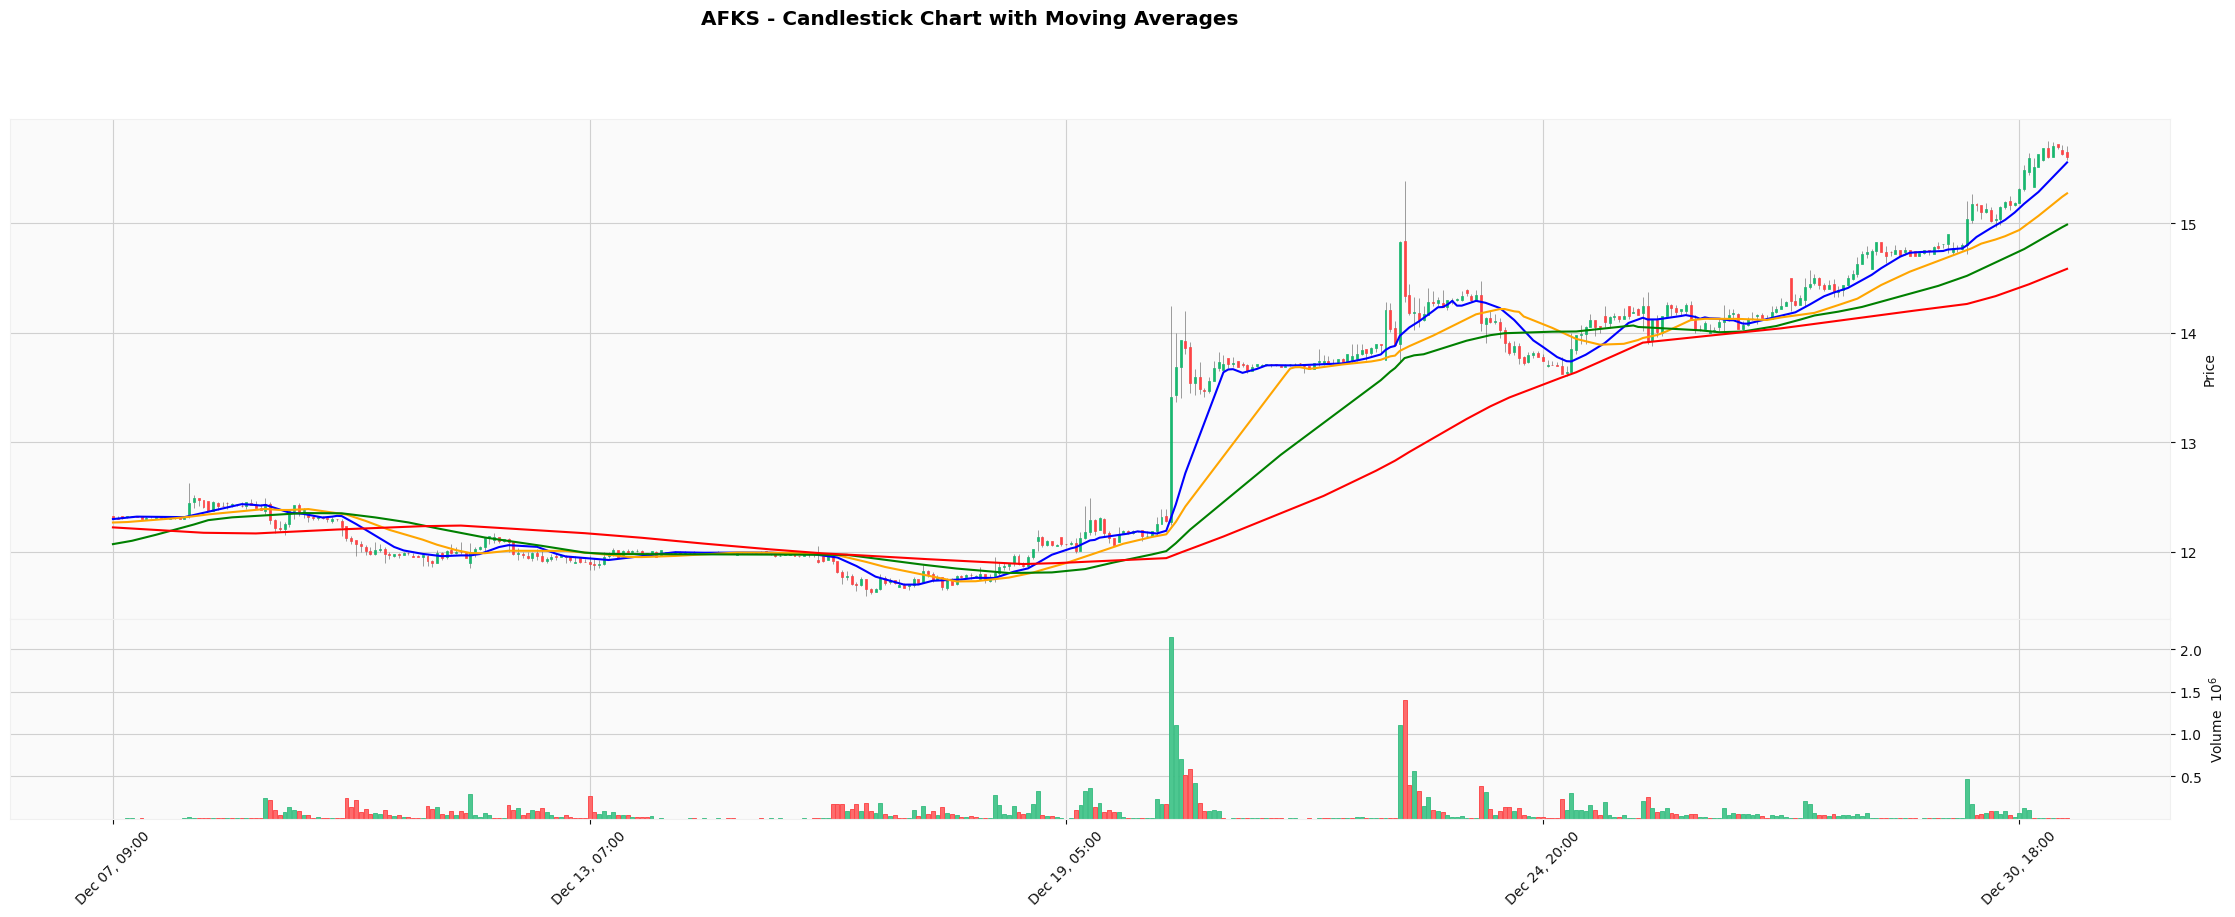

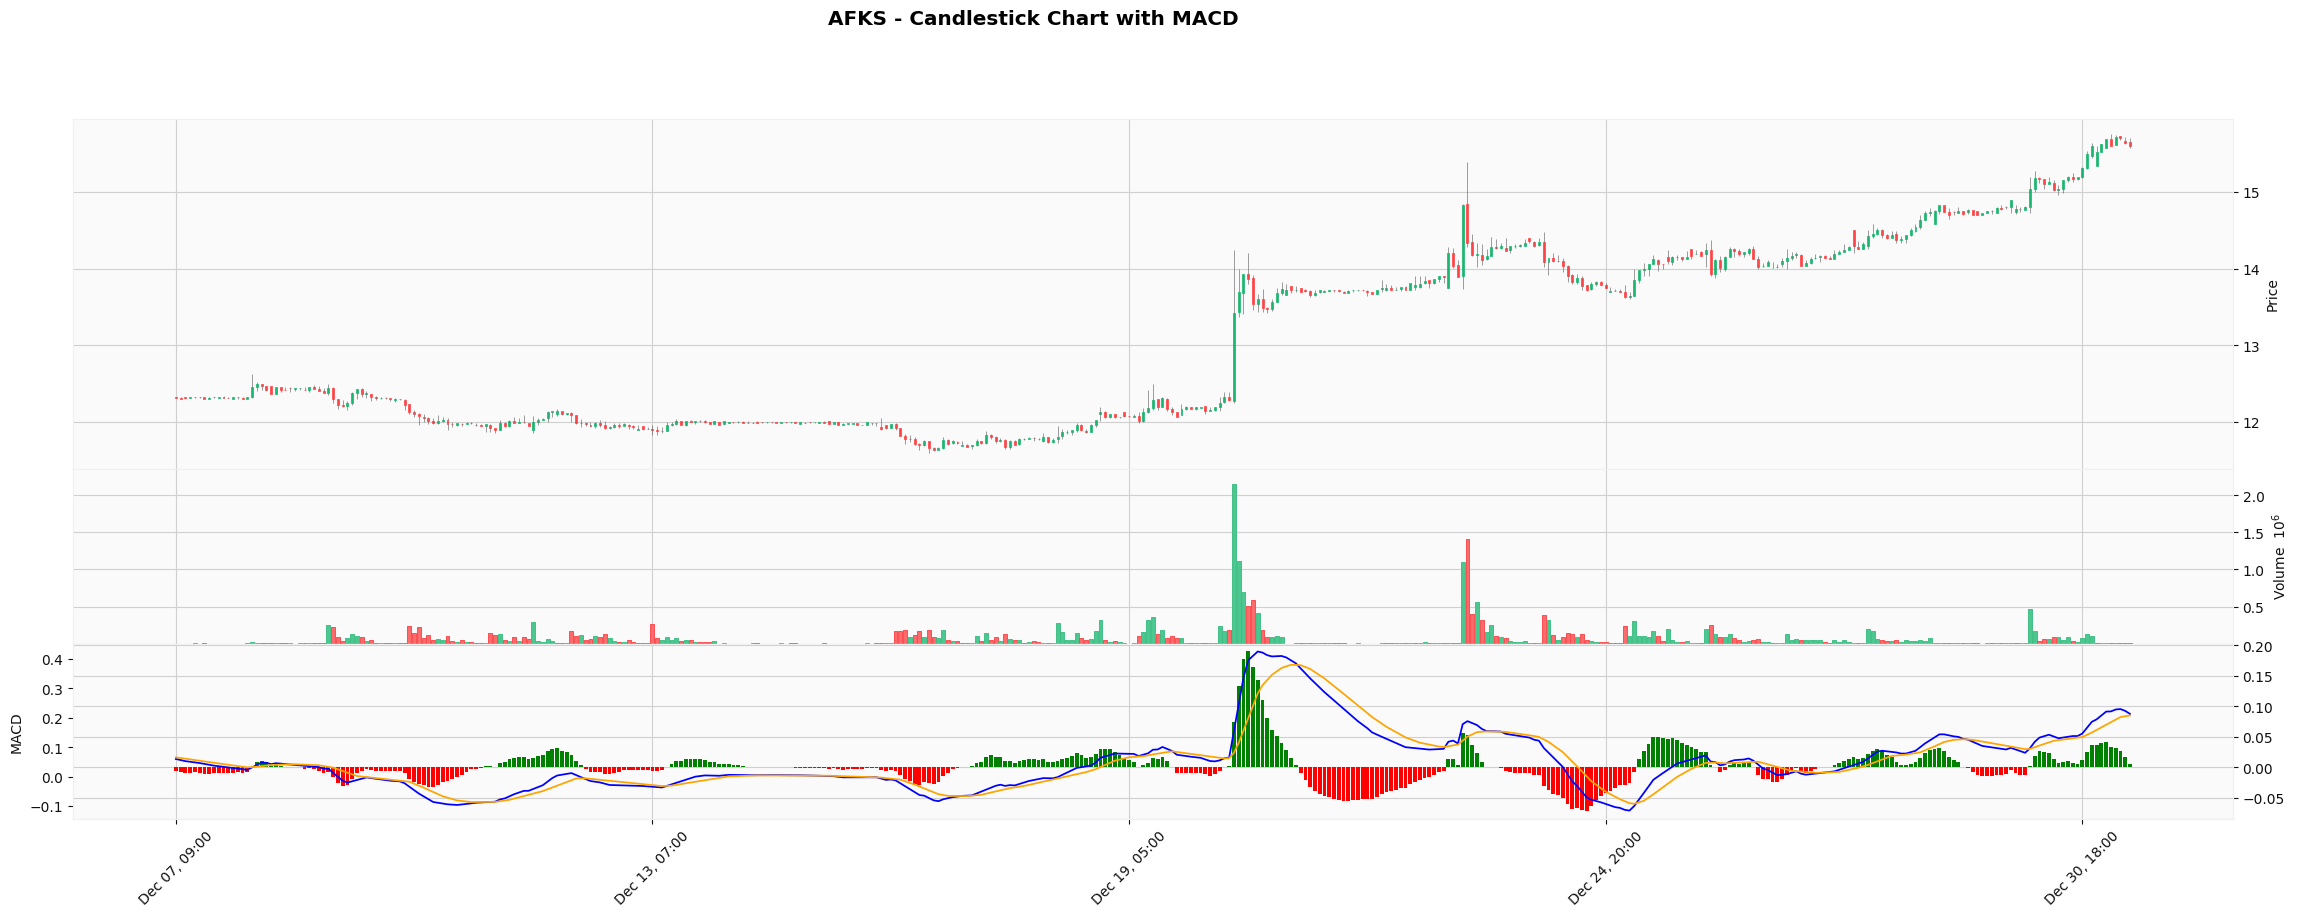

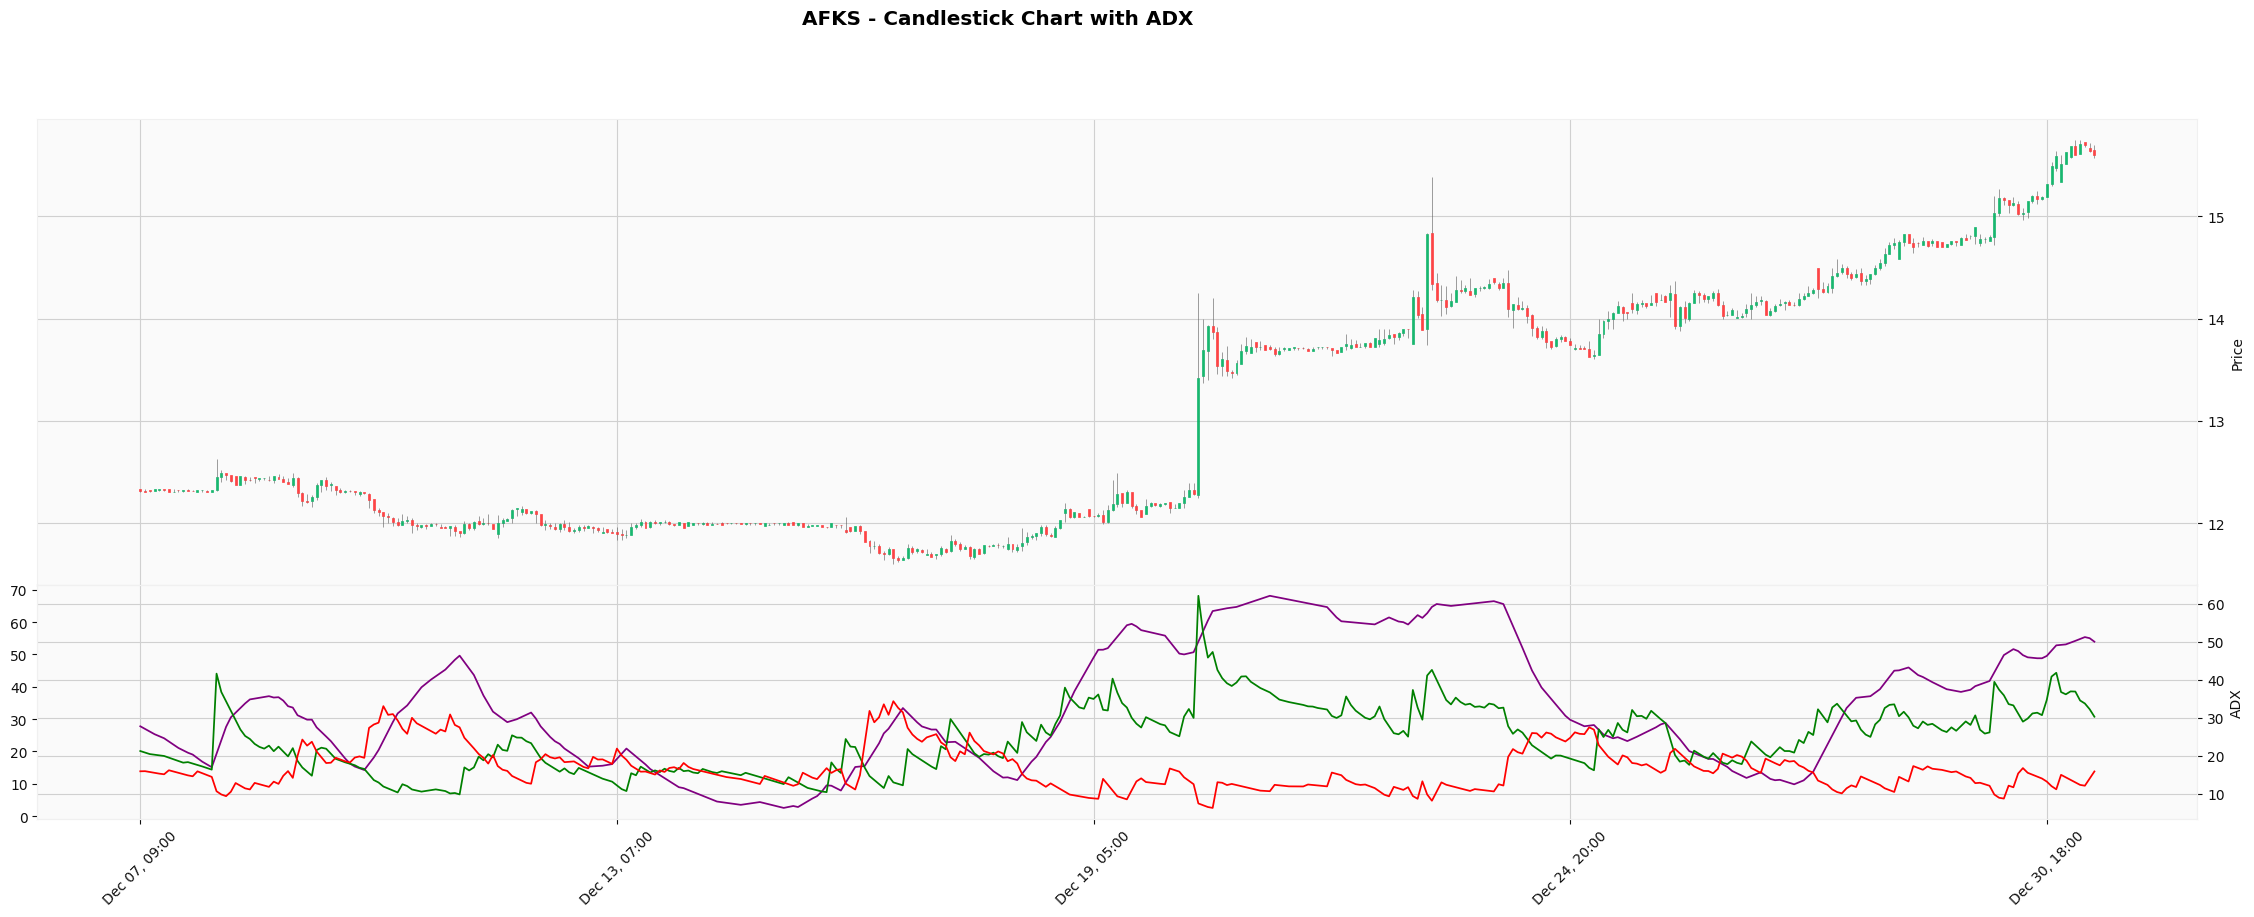

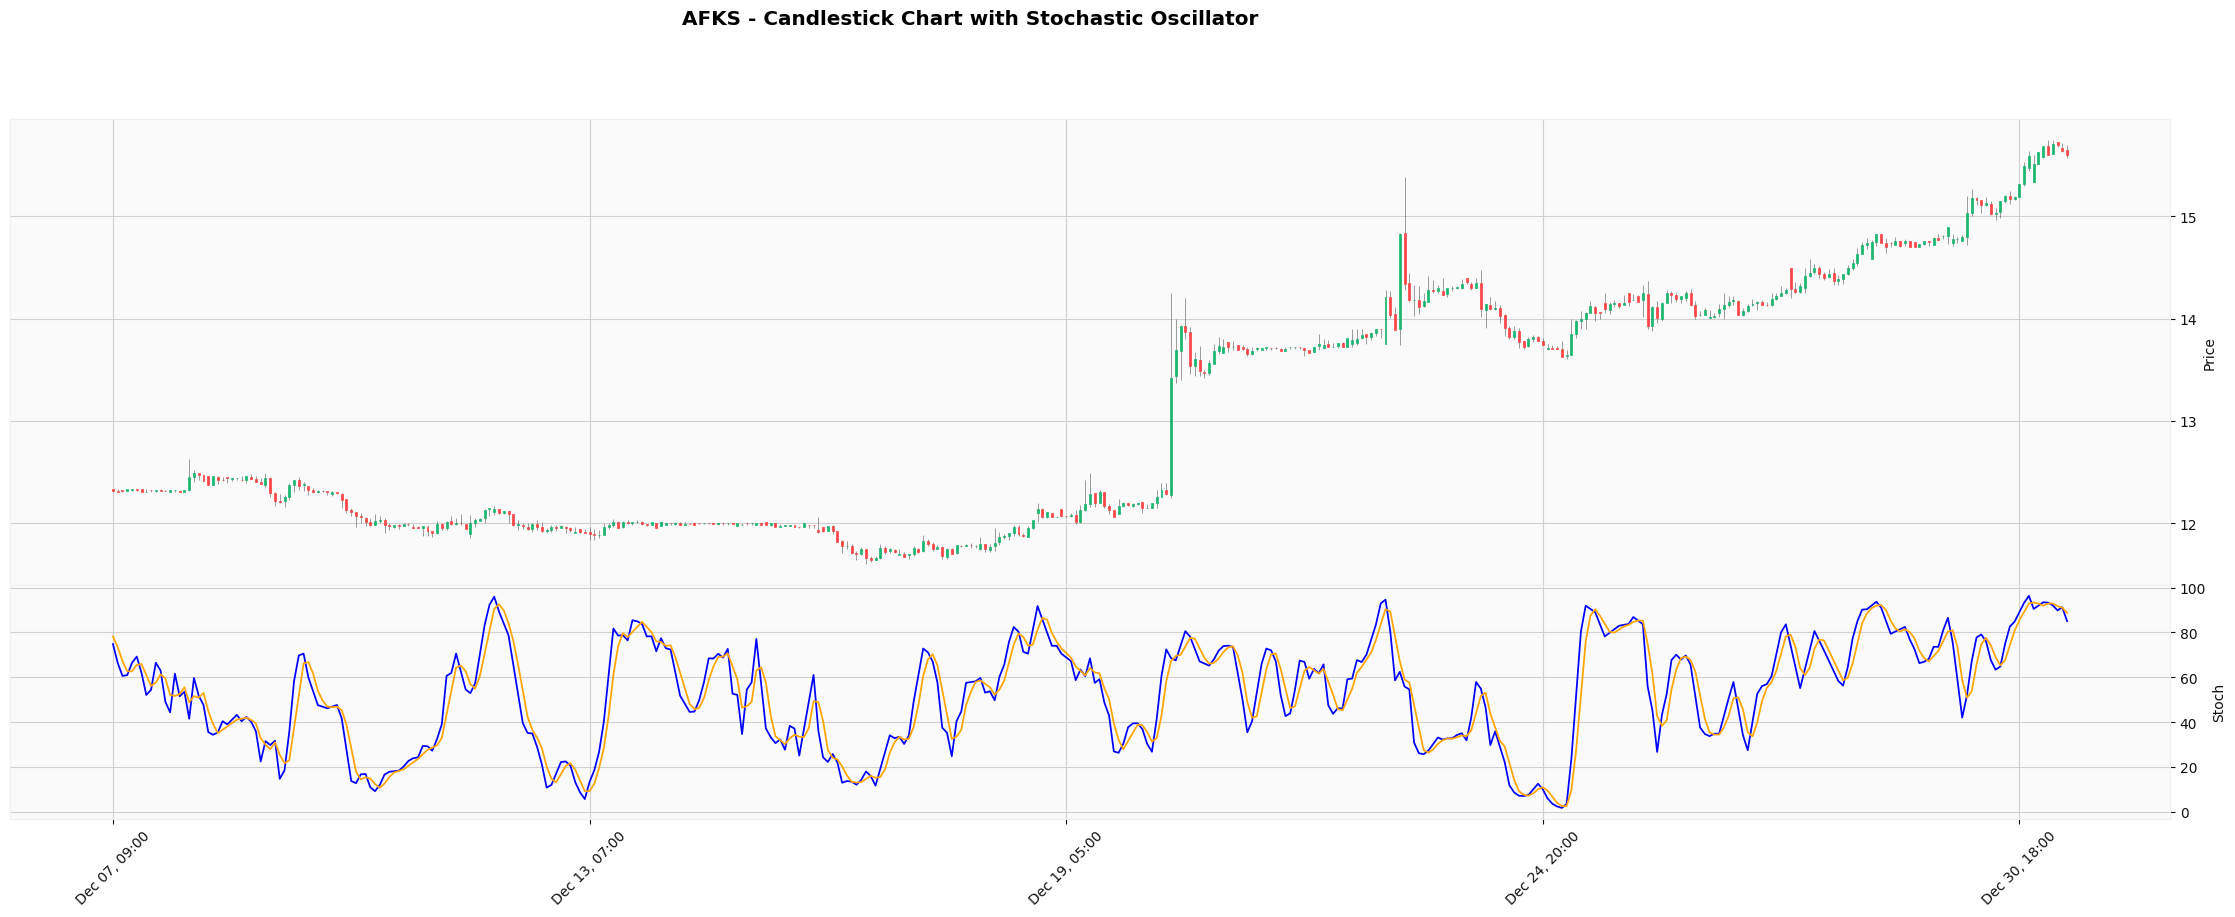

In [4]:
# Select ticker to visualize
ticker = "AFKS"
end_date = pd.Timestamp("2024-12-31T12:00:00Z")
chart_df = df[df['tic'] == ticker]

# The index is already DatetimeIndex, so we can filter directly
filter_date = pd.Timestamp(end_date - timedelta(days=30))
chart_df = chart_df[chart_df.index >= filter_date]

# Create plot addons for different indicators
bb_upper_plot = mpf.make_addplot(chart_df['bb_upper'], color='green', linestyle='dashdot')
bb_lower_plot = mpf.make_addplot(chart_df['bb_lower'], color='red', linestyle='dashdot')
bb_middle_plot = mpf.make_addplot(chart_df['bb_middle'], color='blue')

rsi_plot = mpf.make_addplot(chart_df['rsi'], panel=1, color='purple', ylabel='RSI')

macd_line = mpf.make_addplot(chart_df['macd_line'], panel=2, color='blue', ylabel='MACD')
macd_signal = mpf.make_addplot(chart_df['macd_signal'], panel=2, color='orange')
macd_histogram = mpf.make_addplot(chart_df['macd_histogram'], type='bar', panel=2, 
                                 color=['green' if v >= 0 else 'red' for v in chart_df['macd_histogram']])

sma_12_plot = mpf.make_addplot(chart_df['sma_12'], color='blue', width=1.5)
sma_26_plot = mpf.make_addplot(chart_df['sma_26'], color='orange', width=1.5)
sma_50_plot = mpf.make_addplot(chart_df['sma_50'], color='green', width=1.5)
sma_100_plot = mpf.make_addplot(chart_df['sma_100'], color='red', width=1.5)

# 1. Plot candlestick chart with Bollinger Bands
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with Bollinger Bands",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[bb_upper_plot, bb_middle_plot, bb_lower_plot])

# 2. Plot candlestick chart with RSI
mpf.plot(chart_df, type='candle', volume=False, 
         title=f"{ticker} - Candlestick Chart with RSI",
         style='yahoo', 
         figsize=(30, 10),
         addplot=[rsi_plot])

# 3. Plot candlestick chart with all SMAs
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with Moving Averages",
         style='yahoo',
         figsize=(30, 10),
         addplot=[sma_12_plot, sma_26_plot, sma_50_plot, sma_100_plot])

# 4. Plot candlestick chart with MACD
mpf.plot(chart_df, type='candle', volume=True,
         title=f"{ticker} - Candlestick Chart with MACD",
         style='yahoo',
         figsize=(30, 10),
         addplot=[macd_histogram, macd_line, macd_signal],
         panel_ratios=(2, 1))

# Create plots for ADX and Stochastic
adx_plot = mpf.make_addplot(chart_df['adx'], panel=1, color='purple', ylabel='ADX')
adx_pos_plot = mpf.make_addplot(chart_df['adx_positive'], panel=1, color='green')
adx_neg_plot = mpf.make_addplot(chart_df['adx_negative'], panel=1, color='red')

stoch_k_plot = mpf.make_addplot(chart_df['stoch_k'], panel=1, color='blue', ylabel='Stoch')
stoch_d_plot = mpf.make_addplot(chart_df['stoch_d'], panel=1, color='orange')

# 5. Plot candlestick chart with ADX
# ADX > 25 indicates a strong trend (either up or down)
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with ADX",
         style='yahoo',
         figsize=(30, 10),
         addplot=[adx_plot, adx_pos_plot, adx_neg_plot],
         panel_ratios=(2, 1))

# 6. Plot candlestick chart with Stochastic Oscillator
# Values over 80 indicate overbought, under 20 indicate oversold
mpf.plot(chart_df, type='candle', volume=False,
         title=f"{ticker} - Candlestick Chart with Stochastic Oscillator",
         style='yahoo',
         figsize=(30, 10),
         addplot=[stoch_k_plot, stoch_d_plot],
         panel_ratios=(2, 1))

## Understanding the Technical Indicators

1. **Bollinger Bands**
   - Three lines: Upper, Middle (20-day SMA), and Lower bands
   - Upper/Lower bands are 2 standard deviations from the middle band
   - Price touching the upper band might indicate overbought conditions
   - Price touching the lower band might indicate oversold conditions

2. **Relative Strength Index (RSI)**
   - Momentum oscillator measuring speed and change of price movements
   - Values range from 0 to 100
   - Above 70 typically indicates overbought conditions
   - Below 30 typically indicates oversold conditions

3. **Moving Averages (SMA)**
   - SMA 12, 26, 50, and 100 periods shown
   - Shorter periods (12, 26) for short-term trends
   - Longer periods (50, 100) for long-term trends
   - Crossovers can signal trend changes

4. **MACD (Moving Average Convergence Divergence)**
   - Blue line: MACD line (12-day EMA minus 26-day EMA)
   - Orange line: Signal line (9-day EMA of MACD)
   - Histogram: Difference between MACD and Signal lines
   - Crossovers and divergences can signal trend changes

5. **ADX (Average Directional Index)**
   - Measures trend strength regardless of direction
   - ADX > 25 indicates a strong trend
   - Green line (+DI) shows uptrend strength
   - Red line (-DI) shows downtrend strength

6. **Stochastic Oscillator**
   - Shows momentum by comparing closing price to price range
   - Blue line (K): Fast stochastic
   - Orange line (D): Slow stochastic
   - Above 80 indicates overbought
   - Below 20 indicates oversold

# Env stage 1: Skeleton with visual play

## Goal: Get the basic OHLCV multi-ticker window working with visual rendering ⏱️ ~3–4h

Tasks:
 1. Build environment scaffolding with Gym-style API: reset, step, render

 2. Load small subset of your OHLCV + indicators data for 3–5 assets

 3. Implement state windowing: e.g., [n_assets, n_timesteps, n_features]

 4. Add deterministic agent: equal weight every step

 5. render() plots: portfolio value over time + asset allocations

Dopamine Hit:
Visualize the portfolio value curve of a dumb agent

Plot the allocations heatmap over time

Save first simulation gif: "env_baseline.gif"

In [6]:
# Read df with index
df = pd.read_csv("./data/data/test_ohlcv_data_indicators.csv", index_col='date')
# Set directory for visualization output
output_dir = "./data/visualizations/test_env"
# Ensure output directory exists
os.makedirs(output_dir, exist_ok=True)

In [14]:
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt
import mplfinance as mpf

class PortfolioEnv(gym.Env):
    """A simple portfolio management environment with Gym API."""
    
    def __init__(self, df, window_size=10, n_assets=3):
        super(PortfolioEnv, self).__init__()
        
        # Data parameters
        self.df = df
        self.window_size = window_size
        self.n_assets = n_assets
        
        # Get unique tickers and select first n_assets
        self.tickers = df['tic'].unique()[:n_assets]
        
        # Filter data for selected assets and prepare timesteps
        self.data = df[df['tic'].isin(self.tickers)].copy()
        self.prepare_data()
        
        # Get features for state space (OHLCV + indicators)
        self.features = ['open', 'high', 'low', 'close', 'volume', 
                        'rsi', 'macd_line', 'bb_middle']
        
        # Calculate state and action space dimensions
        self.n_features = len(self.features)
        obs_dim = (self.n_assets, self.window_size, self.n_features)
        
        # Define action and observation spaces
        self.action_space = spaces.Box(low=0, high=1, shape=(self.n_assets,))
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=obs_dim
        )
        
        # Trading variables
        self.current_step = None
        self.portfolio_value = None
        self.weights = None
        self.returns_history = None
        self.weights_history = None
        self.timestamps_history = None
        self.frame_count = 0
        
        # Get unique timestamps for stepping
        self.timestamps = self.data.index.unique()
        
        # Calculate the maximum valid step
        # We need window_size observations before and 1 observation after for returns
        self.max_step = len(self.timestamps) - 2
        self.valid_step_range = range(self.window_size, self.max_step)
        
    def prepare_data(self):
        """Prepare data structures for efficient access."""
        # Find the minimum length among all ticker data
        min_length = float('inf')
        ticker_dfs = {}
        
        for ticker in self.tickers:
            # Get data for this ticker
            ticker_df = self.data[self.data['tic'] == ticker].copy()
            ticker_df = ticker_df.reset_index(drop=True)
            ticker_dfs[ticker] = ticker_df
            min_length = min(min_length, len(ticker_df))
        
        # Trim all DataFrames to the same length
        self.ticker_data = {
            ticker: df.iloc[:min_length].copy() 
            for ticker, df in ticker_dfs.items()
        }
        
        # Update max_step based on actual data length
        self.max_step = min_length - 1
    
    def _get_observation(self):
        """Get the state observation window."""
        obs = np.zeros((self.n_assets, self.window_size, self.n_features))
        
        for i, ticker in enumerate(self.tickers):
            # Get data window for current ticker
            asset_data = self.ticker_data[ticker].iloc[
                self.current_step - self.window_size:self.current_step
            ]
            
            # Fill observation array with normalized features
            for j, feature in enumerate(self.features):
                values = asset_data[feature].values
                # Simple normalization
                mean = np.mean(values) if len(values) > 0 else 0
                std = np.std(values) if len(values) > 0 else 1
                obs[i, :, j] = (values - mean) / (std + 1e-8)
                
        return obs
    
    def reset(self, seed=None):
        """Reset the environment to initial state."""
        super().reset(seed=seed)
        
        # Set initial position
        self.current_step = self.window_size
        self.portfolio_value = 1.0  # Start with $1
        self.weights = np.ones(self.n_assets) / self.n_assets  # Equal weights
        self.returns_history = []
        self.weights_history = []
        self.timestamps_history = []
        self.frame_count = 0
        
        return self._get_observation(), {}
    
    def step(self, action):
        """Execute one step in the environment."""
        # Safety check for end of data
        if self.current_step >= self.max_step:
            return self._get_observation(), 0.0, True, False, {
                'portfolio_value': self.portfolio_value,
                'weights': self.weights
            }
        
        # Verify we have enough data for the next step
        next_step = self.current_step + 1
        if next_step >= self.max_step:
            return self._get_observation(), 0.0, True, False, {
                'portfolio_value': self.portfolio_value,
                'weights': self.weights
            }
        
        # Normalize action to ensure weights sum to 1
        self.weights = action / np.sum(action)
        
        # Store weights history
        self.weights_history.append(self.weights.copy())
        self.timestamps_history.append(self.current_step)
        
        # Get returns for current timestep
        current_returns = []

        for ticker in self.tickers:
            ticker_df = self.ticker_data[ticker]
            # Add safety checks
            if self.current_step >= len(ticker_df) or next_step >= len(ticker_df):
                return self._get_observation(), 0.0, True, False, {
                    'portfolio_value': self.portfolio_value,
                    'weights': self.weights
                }
            
            current_price = ticker_df.iloc[self.current_step]['close']
            next_price = ticker_df.iloc[next_step]['close']
            ret = (next_price / current_price) - 1
            current_returns.append(ret)

        # Calculate portfolio return
        portfolio_return = np.sum(self.weights * current_returns)
        self.portfolio_value *= (1 + portfolio_return)
        self.returns_history.append(self.portfolio_value)
        
        # Move to next step
        self.current_step += 1
        done = self.current_step >= self.max_step
        
        # Get next observation
        obs = self._get_observation()
        
        # Simple reward is the portfolio return
        reward = portfolio_return
        
        return obs, reward, done, False, {
            'portfolio_value': self.portfolio_value,
            'weights': self.weights
        }
        
    def render(self):
        """Render the environment's current state."""
        # Create figure with three subplots
        fig = plt.figure(figsize=(15, 15))
        
        # 1. Portfolio value plot
        ax1 = plt.subplot(311)
        ax1.plot(self.returns_history, color='blue', linewidth=2)
        ax1.set_title('Portfolio Value Over Time')
        ax1.set_xlabel('Time Steps')
        ax1.set_ylabel('Portfolio Value ($)')
        ax1.grid(True)
        
        # 2. Current allocations bar chart
        ax2 = plt.subplot(312)
        ax2.bar(x=self.tickers, height=self.weights, color='orange')
        ax2.set_title('Current Portfolio Allocations')
        ax2.set_xlabel('Assets')
        ax2.set_ylabel('Weight')
        ax2.grid(True)
        
        # 3. Allocations heatmap over time
        if len(self.weights_history) > 0:
            ax3 = plt.subplot(313)
            weights_array = np.array(self.weights_history)
            im = ax3.imshow(weights_array.T, aspect='auto', cmap='YlOrRd')
            ax3.set_yticks(range(len(self.tickers)))
            ax3.set_yticklabels(self.tickers)
            ax3.set_title('Portfolio Weights Over Time')
            ax3.set_xlabel('Time Steps')
            ax3.set_ylabel('Assets')
            plt.colorbar(im, ax=ax3)
        
        plt.tight_layout()
        # Save with frame number
        plt.savefig(os.path.join(output_dir, f'portfolio_state_{self.frame_count:04d}.png'))
        plt.close()
        
        self.frame_count += 1

In [15]:
# Create the environment
env = PortfolioEnv(df, window_size=10, n_assets=3)

# Reset environment
observation, _ = env.reset()

# Create a deterministic agent (equal weights)
def equal_weight_agent(observation):
    return np.ones(env.n_assets) / env.n_assets

# Run one episode for 100 steps
done = False
steps_cnt = 0

while not done and steps_cnt < 100:  # Added step limit
    steps_cnt += 1
    # Get action from agent
    action = equal_weight_agent(observation)
    observation, reward, done, truncated, info = env.step(action)
    env.render()

print(f"Final portfolio value: ${info['portfolio_value']:.2f}")

# Create a GIF from the saved images
import glob
from PIL import Image

# Get list of PNG files in chronological order
png_files = sorted(glob.glob(os.path.join(output_dir, 'portfolio_state_*.png')))

# Create GIF
if png_files:
    images = [Image.open(f) for f in png_files]
    images[0].save(
        os.path.join(output_dir, 'env_baseline.gif'),
        save_all=True,
        append_images=images[1:],
        duration=200,
        loop=0
    )

Final portfolio value: $0.96


# Env stage 2: Basic Reward & Behavior Testing

## Goal: Hook up basic return-based reward and see agent react ⏱️ ~4–5h

Tasks:
 1. Compute simple portfolio return at each step

 2. Agent outputs raw scores → softmax() → allocation weights

 3. Reward = portfolio return – cost term (0.1% turnover penalty)

 4. Log & plot: cumulative return, daily returns, allocations

 5. Add simple greedy agent: picks top-returning asset each step

Dopamine Hit:
See greedy agent outperform equal-weight baseline

Render multiple portfolio value curves for comparison

"reward_test_1.gif" = satisfying animated backtest